In [60]:
import time
import random 
from random import randint
import sys
import matplotlib.pyplot as plt

sys.setrecursionlimit(20000)

GLOBAL_SIZES = [100, 500, 1000, 5000, 10000]
GLOBAL_SIZES_EX_2 = [1000, 2000, 5000]
GLOBAL_RUNS = 5

# Experimental Analysis of Sorting Algorithms based on Time Complexity via different type of input data
## 1. Introduction
The goal of this project is to investigate how input size, input order, the number of duplicate elements in the input and the choice of data types affects the sorting algorithms. The experimental resuls will be compared with theoretical time complexity.
## 2. Theoretical Background

Big O notation is used to describe the complexity of an algorithm. It says that the algorithm will complete in a certain number of steps, in relation to the number of items of data being worked on, without giving specifics of how many instructions each step will take to execute. It is possible, therefore, that an algorithm with a lower complexity will complete more slowly than an algorithm where each step is executed very quickly, but which has a greater order of complexity.

There are several common time complexities expressed using Big O notation which are relevant to this project. At the bottom of the hierarchy is $O(1)$, or constant time. Its running time does not depend on the input size. For example, accessing the first element of a Python list using `items[0]` takes constant time.

Another common complexity is $O(N)$, or linear time. The running time grows proportionally to the input size. For example, finding the minimum or maximum value in a list requires inspecting every element in the general case.

An algorithm with a time complexity of $O(N^2)$ is said to have quadratic time complexity. This commonly occurs when an algorithm uses two nested loops that each process up to $N$ elements. The runtime grows quadratically with the size of the input.If the input size doubles, the number of operations may increase by approximately four times.

Next is $O(\log N)$, or logarithmic time. These algorithms reduce the problem size at each step as attempting to guess a hidden number. This kind of algorithm produces a growth curve that peaks at the beginning and slowly flattens out as the size of the input increases. 

An algorithm with a time complexity of $O(N \log N)$ is said to have linearithmic time complexity. It implies that $\log N$ operations will occur $N$ times. In other words, for each of the $N$ elements, a logarithmic operation is done. $O(N \log N)$ time is common in recursive sorting algorithms, binary tree sorting algorithms and most other types of sorts.

An important point to note is that the running time of algorithms depends on both their complexity and their individual operations. For example, an algorithm requiring approximately $10N$ operations and another requiring $1000 N$ operations are both classified as $O(N)$. Therefore, an algorithm with a higher time complexity may execute faster for small inputs, depending on its implementation. Furthermore, an algorithm's performance may vary depending on the input data, which is why its time complexity is often analyzed in terms of three cases: best-case, average-case, and worst-case scenarios. These describe the most favorable, typical, and least favorable running times for inputs of a given size.
$$ \newline $$ 
| Algorithm | Best Case | Average Case | Worst Case |
| :--- | :---: | :---: | :---: |
| **Selection Sort** | $O(n^2)$ | $O(n^2)$ | $O(n^2)$ |
| **Insertion Sort** | $O(n)$ | $O(n^2)$ | $O(n^2)$ |
| **Bubble Sort** | $O(n)$ | $O(n^2)$ | $O(n^2)$ |
| **Merge Sort** | $O(n \log n)$ | $O(n \log n)$ | $O(n \log n)$ |
| **Quick Sort** | $O(n \log n)$ | $O(n \log n)$ | $O(n^2)$ |



## 3. Algorithm Implementations

### 3.1. Selection Sort
   
Selection sort works in a straightforward manner. It begins by searching the unsorted array for the smallest key, then swapping it into the first position in the array. This key is now the first element of a sorted array, being built from the left. The remainder of the array is still unsorted, and it is now searched for its smallest key, which is swapped into place. This continues until the entire array is sorted.


In [2]:
def selection_sort(items):
    """
    It sorts an array by repeatedly finding the smallest (or largest) element 
    from the unsorted portion and placing it in its correct position.
    """
    for step in range(len(items)):
        # Find the location of the smallest element in
        # items[step:]
        location_of_smallest = step
        for location in range(step, len(items)):
            # Determine location of smallest
            if items[location] < items[location_of_smallest]:
                location_of_smallest = location
        # Exchange items[step] with items[location_of_smallest]
        items[step], items[location_of_smallest] =  items[location_of_smallest],  items[step] 

    return items

### 3.2 Insertion Sort
   
Insertion sort, as its name suggests, is used to insert a single key into its correct position in a sorted list. Beginning with a sorted array of length one, the key to the right of the sorted array is swapped down the array a key at a time, until it is in its correct position. The entire array is sorted in this manner.

In [14]:
def insertion_sort(items):
    """
    It takes each element from the unsorted portion and inserts it 
    into the correct position in the sorted portion
    """
    for step in range(1, len(items)):
        # Start from index 1 because the first element alone is already sorted.
        current_item = items[step]
        location = step
        # Move larger elements one position to the right to make room for current_item.
        while location > 0 and items[location - 1] > current_item:
            # if the previous item is bigger than the current the while loop keep going and storing the current item at tha same position as its previous until reaches zero
            items[location] = items[location - 1]
            location -= 1

        # Insert current_item into its correct position in the sorted part.
        items[location] = current_item

    return items
    

### 3.3. Bubble Sort

Bubblesort, as its name suggests, works by bubbling small keys from right of the array to the left. It
begins by taking a key from the end and moving it left while it is less than any keys it passes. Once it
comes across a smaller key, it changes to this key, and moves it towards the left of the array. In this way,
every iteration the smallest key moves left to its ¯nal position, and other small keys are slowly moved
left, so that the unsorted part of the array becomes more sorted as bubblesort continues.

In [15]:
def bubble_sort(items):
    """
    It repeatedly compares adjacent elements in the list and 
    swaps them if they are in the wrong order.
    """
    n = len(items)

    # Go through the list to sort the items
    for i in range(n):
        
        # Assume that the list is already sorted
        swapped = False

        # Compare neighboring items.
        # After each pass, the largest unsorted item
        # moves to its correct position at the end.
        for j in range(0, n - i - 1):

            # If the current item is greater than the next one,
            # swap them to put them in the correct order.
            if items[j] > items[j + 1]:
                items[j], items[j + 1] = items[j + 1], items[j]
                # Remember that at least one swap happened
                swapped = True

        # If no swaps happened, the list is already sorted.
        # Stop early because there is nothing left to sort.
        if not swapped:
            break

    return items

### 3.4. Merge Sort

Mergesort works by treating an unsorted array of length $N$ as $N$ sorted arrays of length one. It then
merges the first two arrays into one array of length two, and likewise for all other pairs. These arrays are then merged with their neighbours into arrays of length four, then eight, and so on until the arrays are completely sorted.

In [16]:
def merge_sort(arr):
    """
    It divides an input array into two halves, recursively sorts them,
    and then merges the two sorted halves using a function called merge().
    """
    if len(arr) <= 1:
        return arr

    mid = len(arr) // 2
    left_half = merge_sort(arr[:mid])
    right_half = merge_sort(arr[mid:])

    return merge(left_half, right_half)

def merge(left, right):
    sorted_list = []
    i = j = 0

    while i < len(left) and j < len(right):
        if left[i] < right[j]:
            sorted_list.append(left[i])
            i += 1
        else:
            sorted_list.append(right[j])
            j += 1

    sorted_list.extend(left[i:])
    sorted_list.extend(right[j:])
    
    return sorted_list

### 3.5. Quick Sort

Quicksort is an algorithm of the type known as divide and conquer. It recursively partitions its array
around a pivot, swapping large keys on the left hand side with smaller keys on the right hand side. The
partition causes the pivot to be put in its final position, with all greater keys to the right, and lesser keys
on the left. The left and right partitions are then sorted recursively.

In [17]:
def quick_sort(array):
    """
    Quick sort recursively partitions its array around a pivot, 
    swapping large keys on the left hand side with smaller keys on the right hand side.
    """
    # If the input array contains fewer than two elements,
    # then return it as the result of the function
    if len(array) < 2:
        return array

    low, same, high = [], [], []

    # Select your `pivot` element randomly
    pivot = array[randint(0, len(array) - 1)]

    for item in array:
        # Elements that are smaller than the `pivot` go to
        # the `low` list. Elements that are larger than
        # `pivot` go to the `high` list. Elements that are
        # equal to `pivot` go to the `same` list.
        if item < pivot:
            low.append(item)
        elif item == pivot:
            same.append(item)
        elif item > pivot:
            high.append(item)

    # The final result combines the sorted `low` list
    # with the `same` list and the sorted `high` list
    return quick_sort(low) + same + quick_sort(high)

## 4. Experimental Methology

### 4.1. Input Sizes

The experiments use different input sizes depending on the expected time complexity of the sorting algorithms. Bubble Sort, Insertion Sort, and Selection Sort are tested on smaller arrays because their average and worst-case time complexities are quadratic, $O(n^2)$. Merge Sort and Quick Sort are tested on larger arrays to investigate their performance as the input size increases.

The initial input sizes are:

- **Quadratic algorithms:** 100, 500, 1,000, 2,000, and 5,000 elements.
- **More efficient algorithms:** 1,000, 10,000, 100,000, and 1,000,000 elements.

The input sizes may be adjusted depending on the execution time and available system memory.

### 4.2. Data Generation

Random floating-point numbers are generated using Python's `random.random()` function. This function produces values in the interval $[0,1]$.

A fixed random seed is used to make the experiments reproducible. For each input size, one original array is generated and reused across the algorithms being compared. Each algorithm receives a separate copy of the same array to ensure that all implementations process identical input data.

### 4.3. Execution Time Measurement

The execution time is measured using Python's `time.perf_counter()` function, which provides a high-resolution performance counter.

Only the sorting operation is included in the measured interval. Input generation, array copying, printing, and correctness checks are performed outside the timed section.

### 4.4. Repetitions and Statistical Measurement

Each experiment is repeated five times when computationally practical. The median execution time is calculated from the recorded measurements and used for comparison. The median reduces the influence of unusually high or low measurements caused by background processes or other system activity.

For computationally expensive experiments, the number of repetitions may be reduced and explicitly reported.

### 4.5. Ensuring a Fair Comparison

To ensure a fair comparison, the following conditions are maintained:

- All algorithms being compared receive identical input values in the same initial order.
- A separate copy of the original array is provided to each algorithm.
- The same timing method is used for every implementation.
- Array generation and copying are excluded from the measured sorting time.
- The correctness of each result is verified after timing.
- Experiments are conducted in the same computing environment whenever possible.

The results are presented using tables and graphs to examine how execution time changes with input size and how the observed performance relates to the theoretical time complexity of each algorithm.

## 5.Experiments and Result

### 5.1. Effect of Input Size
#### 5.1.1 Research question
How does the input size affect the execution time of each sorting algorithm?
#### 5.1.2. Hypothesis
Algorithms with $O(N^2)$ time complexity are expected to become slower more rapidly than algorithms with $O(N \log N)$ complexity as the input size increases.
#### 5.1.3. Method 
Generate arrays of different sizes, run each algorithm on equivalent input data, repeat the measurements, and calculate the median execution time.
#### 5.1.4. Implementation

In [18]:
def get_sorting_algorithms():
    """ 
    Gathers the previously defined sorting functions into a dictionary.
    Returns a dictionary where keys are algorithm names and values are the function objects.
    """
    return {
        "Selection Sort": selection_sort,
        "Insertion Sort": insertion_sort,
        "Bubble Sort": bubble_sort,
        "Merge Sort": merge_sort,
        "Quick Sort": quick_sort
    }
    
# Activate the global dictionary containing the sorting algorithms
my_algorithms = get_sorting_algorithms()


In [ ]:
def compare_input_size(algorithms):
    """
    Compares different types of algorithms with various input sizes.
    Return a dictionary with the mean time complexity
    """
    # initializes the whole results dictionary once.
    results = {}

    # iterates each algorithm with the specific size and when its done with all the algorithms goes to another input size 
    for size in GLOBAL_SIZES:
        print(f"Experiment 1 with input size N = {size}")
        # initializes a separate inner dictionary for each input size.
        results[size] = {}

        # Generates random array with unsorted numbers
        base_data = [random.randint(1, 100000) for _ in range(size)]

        # iterates through every algorithm in the global dictionary 
        for name, algo_func in algorithms.items():
            total_time = 0

            for _ in range(GLOBAL_RUNS):
                # copies the base array so each algorithm has equivalent input data
                data_copy = base_data.copy()

                # Time measurements
                start_time = time.perf_counter()
                # this calls the sorting function using the copied array and "_" is that we don't need to use the function's returned value.
                _ = algo_func(data_copy)
                end_time = time.perf_counter()
                
                total_time += (end_time - start_time)

            # calculates the avg time of each algorithm based on the runs
            avg_time = total_time / GLOBAL_RUNS
            # stores the result of the current input size
            results[size][name] = avg_time

    return results

# ==========================================
# STARTS EXPERIMENT 1
# ==========================================
experiment_results = compare_input_size(my_algorithms)

# Prints table
print("\n" + "="*95)
print("FINAL RESULTS (AVG TIME IN SECONDS)")
print("="*95)

header = f"{'Input Size (N)':<12}"
for algo_name in my_algorithms.keys():
    header += f" | {algo_name:<14}"
print(header)
print("-" * len(header))

for size in GLOBAL_SIZES:
    row = f"{size:<12}"
    for algo_name in my_algorithms.keys():
        avg_time = experiment_results[size][algo_name]
        row += f" | {avg_time:<14.6f}"
    print(row)


Experiment 1 with input size N = 100
Experiment 1 with input size N = 500
Experiment 1 with input size N = 1000
Experiment 1 with input size N = 5000
Experiment 1 with input size N = 10000


#### 5.1.4. Results and Analysis

In [ ]:
plt.figure(figsize=(12, 7))

#
for algo_name in my_algorithms.keys():
    times = []

    for size in GLOBAL_SIZES:
        avg_times = experiment_results[size][algo_name]
        times.append(avg_times)

    plt.plot(GLOBAL_SIZES, times, marker="o", label=algo_name)

plt.xlabel("Input Size (N)", fontsize=12)
plt.ylabel("Average Running Time (seconds)", fontsize=12)
plt.title("Sorting Algorithms: Input Size vs Running Time", fontsize=14)

plt.xscale("log")
plt.yscale("log")

plt.xticks(GLOBAL_SIZES, [f"{size:,}" for size in GLOBAL_SIZES], rotation=30)
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

As expected $O(N^2)$ are slower than  $O(N \log N)$ when we iterate the algorithms with

### 5.2. Effect of Input Order
#### 5.2.1. Research question
How does the input order change the result of each sorting algorithm?
#### 5.2.2. Hypothesis

#### 5.2.3. Method 
Generate arrays of different input order - sorted, almost sorted,reverse and random, run each algorithm on equivalent input data, repeat the measurements, and calculate the median execution time.
#### 5.2.4. Implementation


In [56]:
def select_input_data(arr):
    """
    Generate different input orders for sorting algorithms.
    """

    # Fully sorted array in ascending order
    sorted_data = sorted(arr)

    # Fully sorted array in descending order
    reverse_data = sorted(arr, reverse=True)

    # Random order
    random_data = arr.copy()
    random.shuffle(random_data)

    # Almost sorted array
    almost_sorted_data = sorted(arr)

    n = len(almost_sorted_data)

    for i in range(0, n - 1, 2):
        almost_sorted_data[i],  almost_sorted_data[i + 1] = (
            almost_sorted_data[i + 1],
            almost_sorted_data[i]
        )
   
    return {
        "Sorted": sorted_data,
        "Reverse": reverse_data,
        "Random": random_data,
        "Almost Sorted": almost_sorted_data
    }

In [50]:
arr = [random.randint(1, 1000) for _ in range(50)]
input_data = select_input_data(arr)

print("Sorted:", input_data["Sorted"])
print("Reverse:", input_data["Reverse"])
print("Random:", input_data["Random"])
print("Almost Sorted:", input_data["Almost Sorted"])

Sorted: [21, 27, 49, 50, 50, 72, 79, 80, 104, 122, 153, 156, 156, 248, 257, 304, 306, 339, 351, 358, 365, 375, 389, 391, 423, 469, 492, 498, 547, 558, 568, 590, 591, 608, 616, 622, 622, 627, 728, 745, 778, 786, 797, 805, 864, 887, 891, 913, 969, 995]
Reverse: [995, 969, 913, 891, 887, 864, 805, 797, 786, 778, 745, 728, 627, 622, 622, 616, 608, 591, 590, 568, 558, 547, 498, 492, 469, 423, 391, 389, 375, 365, 358, 351, 339, 306, 304, 257, 248, 156, 156, 153, 122, 104, 80, 79, 72, 50, 50, 49, 27, 21]
Random: [616, 622, 365, 122, 568, 79, 153, 72, 786, 805, 627, 608, 306, 257, 797, 469, 498, 423, 391, 21, 80, 375, 27, 913, 492, 591, 558, 891, 50, 778, 622, 248, 547, 745, 304, 728, 995, 864, 339, 156, 358, 156, 50, 104, 969, 49, 590, 887, 389, 351]
Almost Sorted: [27, 21, 50, 49, 72, 50, 80, 79, 122, 104, 156, 153, 248, 156, 304, 257, 339, 306, 358, 351, 375, 365, 391, 389, 469, 423, 498, 492, 558, 547, 590, 568, 608, 591, 622, 616, 627, 622, 745, 728, 786, 778, 805, 797, 887, 864, 913, 891

In [61]:
def compare_input_order(algorithms):
    """
    Compares different types of algorithms with various input sizes.
    Return a dictionary with the mean time complexity
    """
    # initialize the whole results dictionary once.
    results = {}

    # iterate each algorithm with the specific size and when its done with all the algorithms goes to another input size 
    for size in GLOBAL_SIZES_EX_2:
        print(f"Experiment 1 with input size N = {size}")
        # initialize a separate inner dictionary for each input size.
        results[size] = {}

        # Generate random array with unsorted numbers
        base_data = [random.randint(1, 10000) for _ in range(size)]

        # Generate different input orders - sorted, almost sorted, reverse and random
        input_cases = select_input_data(base_data)
        
        # iterates through each input order
        for input_name, input_data in input_cases.items():

            # create a dictionary for the current input
            results[size][input_name] = {}

            # iterate through each sorting algorithm
            for algo_name, algo_func in algorithms.items():
                total_time = 0

                # repeat the measurement
                for _ in range(GLOBAL_RUNS):
                    data_copy = input_data.copy()

                    # time measuremnts
                    start_time = time.perf_counter()
                    algo_func(data_copy)
                    end_time = time.perf_counter()

                    # calculate total time
                    total_time += end_time - start_time

                # calculate the average running time
                avg_time = total_time / GLOBAL_RUNS

                # store the average time
                results[size][input_name][algo_name] = avg_time

    return results



print("\n" + "=" * 110)
print("EXPERIMENT 2: AVG TIME IN SECONDS")
print("=" * 110)

experiment_results = compare_input_order(my_algorithms)
for size in GLOBAL_SIZES_EX_2:
    print(f"\nInput Size: {size}")

    header = f"{'Input Order':<18}"
    for algo_name in my_algorithms.keys():
        header += f" | {algo_name:<16}"

    print(header)
    print("-" * len(header))

    for input_name in experiment_results[size]:
        row = f"{input_name:<18}"

        for algo_name in my_algorithms.keys():
            avg_time = experiment_results[size][input_name][algo_name]
            row += f" | {avg_time:<16.6f}"

        print(row)



EXPERIMENT 2: AVG TIME IN SECONDS
Experiment 1 with input size N = 1000
Experiment 1 with input size N = 2000
Experiment 1 with input size N = 5000

Input Size: 1000
Input Order        | Selection Sort   | Insertion Sort   | Bubble Sort      | Merge Sort       | Quick Sort      
-----------------------------------------------------------------------------------------------------------------
Sorted             | 0.059348         | 0.000241         | 0.000126         | 0.003112         | 0.002564        
Reverse            | 0.051042         | 0.130858         | 0.170260         | 0.002993         | 0.002695        
Random             | 0.046938         | 0.069882         | 0.104521         | 0.004044         | 0.002716        
Almost Sorted      | 0.053626         | 0.000399         | 0.000437         | 0.003709         | 0.003245        

Input Size: 2000
Input Order        | Selection Sort   | Insertion Sort   | Bubble Sort      | Merge Sort       | Quick Sort      
-----------------

#### 5.2.4. Results and Analysis

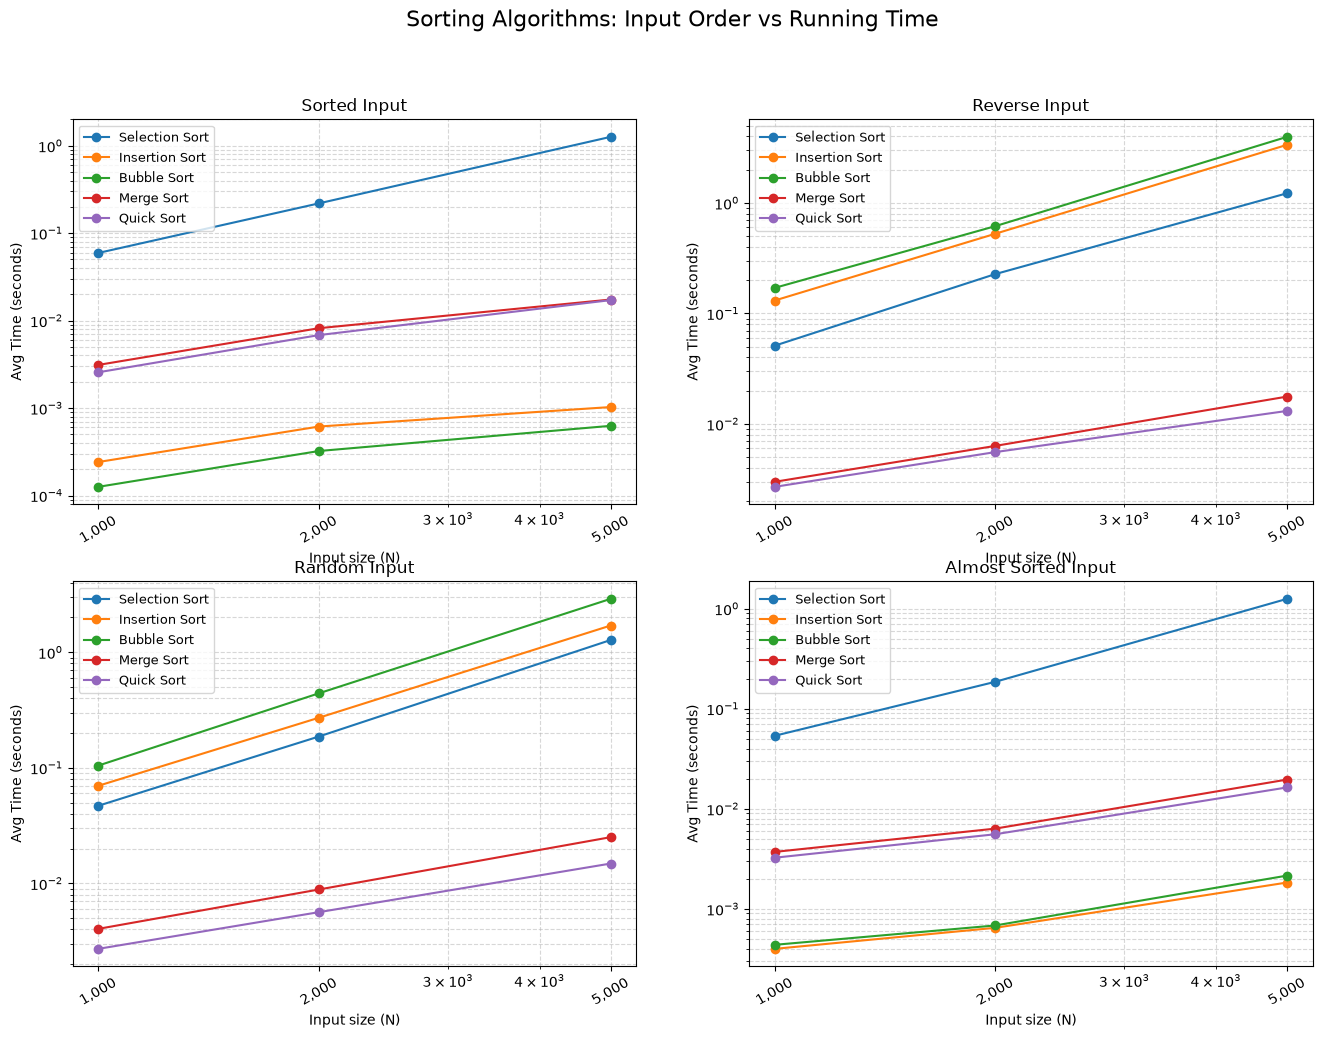

In [62]:
# rearange the space so it can visualize all the diagrams for input order at once
fig, axes = plt.subplots(2,2, figsize = (16, 11))

input_orders = ["Sorted", "Reverse", "Random", "Almost Sorted"]

axes = axes.flatten()

# iterate through each input order 
for i, input_name in enumerate(input_orders):

    # point the ax for the current input order
    ax = axes[i]

    for algo_name in my_algorithms.keys():

        # an array in which we will store the Avg Time Measurements for the current input order of all algorithms
        times = []

        # iterate through sizes
        for size in GLOBAL_SIZES_EX_2:
            avg_time = experiment_results[size][input_name][algo_name]
            times.append(avg_time)

        # draw the diagram 
        ax.plot(
            GLOBAL_SIZES_EX_2, 
            times, 
            marker="o",
            label=algo_name
        )

    # set diagram specifics
    ax.set_title(f"{input_name} Input")
    ax.set_xlabel("Input size (N)")
    ax.set_ylabel("Avg Time (seconds)")

    # visualize the scale with better measurements - appropriate for small difference between the scale
    ax.set_xscale("log")
    ax.set_yscale("log")

    
    ax.set_xticks(GLOBAL_SIZES_EX_2)
    ax.set_xticklabels(
        [f"{size:,}" for size in GLOBAL_SIZES_EX_2],
        rotation = 30
    )

    ax.grid(True, which="both", linestyle="--", alpha=0.5)
    ax.legend(fontsize = 9)

# center titile, main title
fig.suptitle(
    "Sorting Algorithms: Input Order vs Running Time",
    fontsize = 16
)

plt.show()
        